# **Escuela en Computación Cuántica para Informáticos I** (2026)- **UNRN**
# **Modulo I:** Introducción a la computación cuántica y aplicaciones prácticas
**Docente:** Dr. Andrés Alejandro Reynoso - **Ayudante:** Enrique Nicanor Mariotti

## **Día I:** Instalacion de Qiskit

Si tenemos instalado qiskit, ejecutamos la celda de abajo. Si es la primera vez que lo instalamos, no es necesario.

In [ ]:
# 1. Desinstalamos el paquete anterior
#!pip uninstall -y qiskit-transpiler-service

Instalar qiskit en su versión 2.4.2

In [ ]:
# 2. Instalamos Qiskit 2.4.2 y las librerías de IBM Runtime actualizadas
!pip install qiskit==2.4.2 qiskit-ibm-runtime samplomatic

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 28.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 44.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.7/120.7 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 37.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.6/76.6 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.2/130.2 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 25.8 MB/s eta 0:00:00


Luego instalar estas otras librerías que son necesarias.

In [ ]:
%pip install qiskit_aer
%pip install qiskit_ibm_runtime
%pip install matplotlib
%pip install pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 78.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 2.3 MB/s eta 0:00:00


**NOTA:** Testeamos la instalación reiniciando el entorno desde "Entorno de ejecución" -> "Reiniciar la sesión"

Probamos que se haya instalado correctamente e importamos las librerías.

In [1]:
import qiskit
print("Qiskit versión:", qiskit.__version__)

import qiskit_ibm_runtime
print("¡Todo listo y sin conflictos!")

Qiskit versión: 2.5.2
¡Todo listo y sin conflictos!


Probamos crear un circuito simple para probar que este funcionando todo.


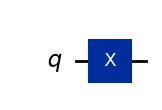

In [2]:
from qiskit import QuantumCircuit

# Crear un nuevo circuito con 1 qubit
qc = QuantumCircuit(1)

# Aplicar una compuerta X (NOT) al qubit 0
qc.x(0)

# Retorna un dibujo del circuito con MatPlotLib ("mpl").
# Esta es la ultima linea de codigo para que el grafico aparezca en la celda.
qc.draw("mpl")

**NOTA:** Cada vez que uses qiskit en Colab (en una nueva sesión) vamos a tener que instalarlo, ya que no es una librería "preinstalada". Ejecutá las celdas 2 y 3, reiniciá el entorno de ejecución y después verificá ejecutanto la celda 4. Ahora podemos seguir adelante.

## **Día I:** Circuitos Básicos y Entrelazamiento



Importar librerias utiles y definir algunas funciones de utilidad para correr los experimentos.

In [ ]:
# Configuración general: import y simulador
import random
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from qiskit import QuantumCircuit, transpile
from qiskit import ClassicalRegister, QuantumRegister

from qiskit_aer import AerSimulator
from qiskit.circuit import Parameter
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import Operator, Statevector
from qiskit.visualization import plot_histogram

sim = AerSimulator()

def run_circuit(qc, shots=1024):
    """Transpila y ejecuta un circuito en el simulador AerSimulator, devuelve counts."""
    # traducir las compuertas logicas que estamos corriendo
    tqc = transpile(qc, sim)
    result = sim.run(tqc, shots=shots).result()  # shots numero de veces para correr el circuito
    return result.get_counts()

### **Experimento 0:** Una compuerta H

Aplicar una `H` pone al qubit en un estado de superposición, el resultado de la medición es equiprobable.

Estado antes de la medición:


<IPython.core.display.Latex object>


Vector de amplitudes complejas:
[0.70710678+0.j 0.70710678+0.j]

Circuito:


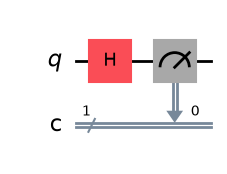


Resultado del experimento: {'0': 515, '1': 509}


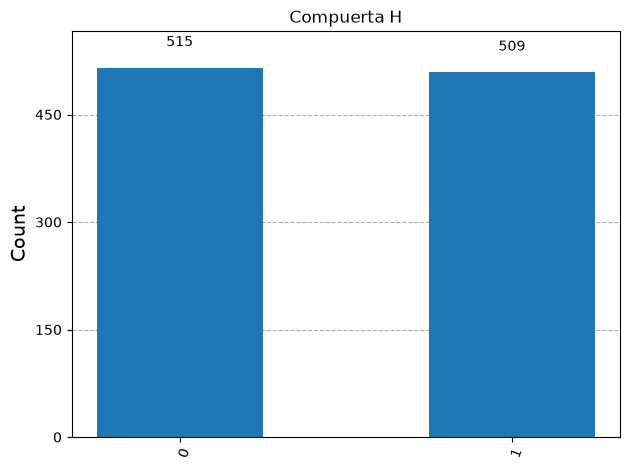

In [ ]:
qc_h = QuantumCircuit(1, 1)
qc_h.h(0)
sv = Statevector(qc_h) # recuperar el vector de estado en ese punto
qc_h.measure(0, 0) # medir en la base z por defecto. Base computacional 

print("Estado antes de la medición:")
display(sv.draw('latex'))

print("\nVector de amplitudes complejas:")
print(sv.data)

print("\nCircuito:")
display(qc_h.draw(output='mpl'))
counts = run_circuit(qc_h)

print("\nResultado del experimento:", counts)
plot_histogram(counts, title="Compuerta H")

### **Experimento 1:** Dos puertas H en sucesión

Aplicar `H` dos veces seguidas **no** es lo mismo que tirar una moneda dos veces. La segunda `H` deshace la superposición creada por el primero, así que el resultado siempre es `0` (interferencia destructiva), a diferencia de dos lanzamientos de moneda independientes.

Estado antes de la medición:


<IPython.core.display.Latex object>


Vector de amplitudes complejas:
[1.+0.j 0.+0.j]

Circuito:


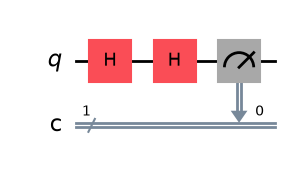


Resultado del experimento: {'0': 1024}


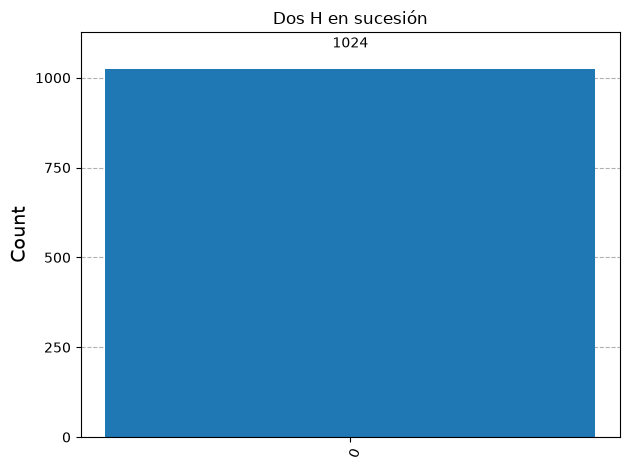

In [6]:
qc_hh = QuantumCircuit(1, 1)
qc_hh.h(0)
qc_hh.h(0)
sv = Statevector(qc_hh)
qc_hh.measure(0, 0)

print("Estado antes de la medición:")
display(sv.draw('latex'))

print("\nVector de amplitudes complejas:")
print(sv.data)

print("\nCircuito:")
display(qc_hh.draw(output='mpl'))
counts = run_circuit(qc_hh)

print("\nResultado del experimento:", counts)
plot_histogram(counts, title="Dos H en sucesión")

### **Experimento 2:** Entrelazamiento de 2 qubits — resultado 00 o 11

Circuito de Bell estándar: `H` sobre `q0` seguido de `CNOT(q0, q1)`. Los dos qubits quedan entrelazados y solo se observan los estados `00` y `11`.

Estado antes de la medición:


<IPython.core.display.Latex object>


Vector de amplitudes complejas:
[0.70710678+0.j 0.        +0.j 0.        +0.j 0.70710678+0.j]

Circuito:


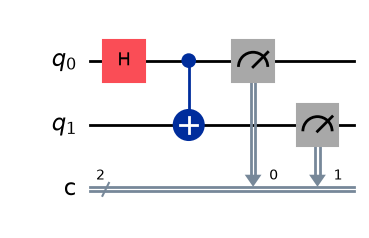


Resultado (solo '00' y '11'): {'00': 528, '11': 496}


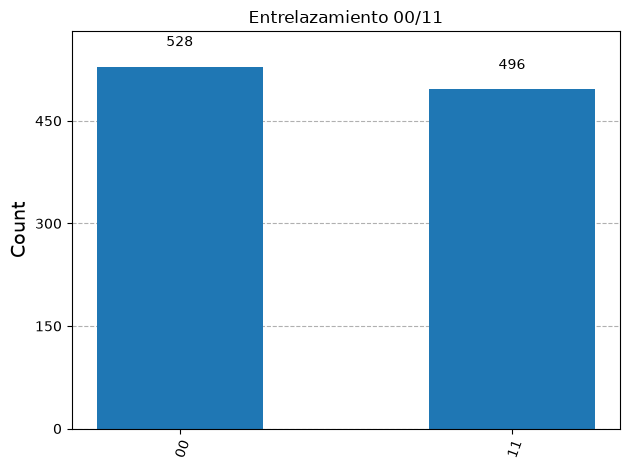

In [8]:
qc_bell = QuantumCircuit(2, 2)
qc_bell.h(0)
qc_bell.cx(0, 1)
sv = Statevector(qc_bell)
qc_bell.measure([0, 1], [0, 1])

print("Estado antes de la medición:")
display(sv.draw('latex'))

print("\nVector de amplitudes complejas:")
print(sv.data)

print("\nCircuito:")
display(qc_bell.draw(output='mpl'))
counts = run_circuit(qc_bell)

print("\nResultado (solo '00' y '11'):", counts)
plot_histogram(counts, title="Entrelazamiento 00/11")

### **Experimento 3:** Entrelazamiento de 2 qubits (q1 inicializado a 1) — resultado 01 o 10

Se agrega una puerta `X` sobre `q1` antes del `H` y `CNOT`. Ahora los estados observados son `01` y `10`. Si `r,s,t,u` son las amplitudes de `00,01,10,11`, los qubits están entrelazados si `ru = st`. Verificamos ambos casos.

Estado antes de la medición:


<IPython.core.display.Latex object>


Vector de amplitudes complejas:
[0.        +0.j 0.70710678+0.j 0.70710678+0.j 0.        +0.j]

Circuito:


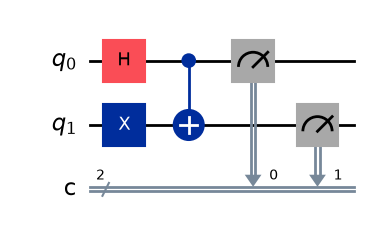


Resultado (solo '01' y '10'): {'01': 501, '10': 523}


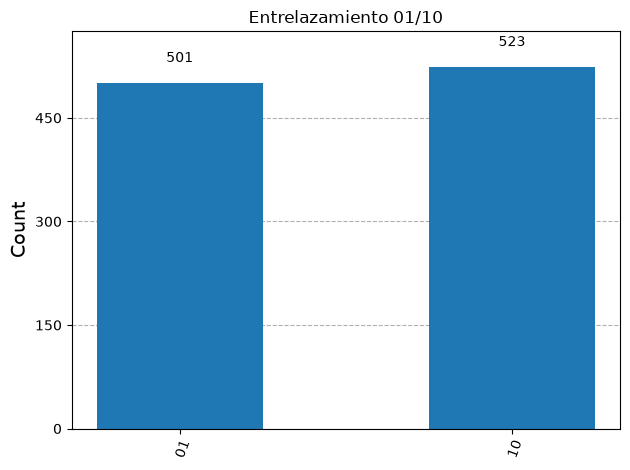

In [9]:
qc_bell2 = QuantumCircuit(2, 2)
qc_bell2.x(1)          # inicializa q1 = 1
qc_bell2.h(0)
qc_bell2.cx(0, 1)
sv = Statevector(qc_bell2)
qc_bell2.measure([0, 1], [0, 1])

print("Estado antes de la medición:")
display(sv.draw('latex'))

print("\nVector de amplitudes complejas:")
print(sv.data)

print("\nCircuito:")
display(qc_bell2.draw(output='mpl'))
counts = run_circuit(qc_bell2)

print("\nResultado (solo '01' y '10'):", counts)
plot_histogram(counts, title="Entrelazamiento 01/10")

In [ ]:
# Verificación de entrelazamiento mediante una instancia de Statevector().
# Sean r,s,t,u las amplitudes de los estados q0q1 = 00,01,10,11.
# Los dos qubits NO están entrelazados (son separables / producto tensorial) si r*u = s*t.
# Si r*u != s*t, los qubits SÍ están entrelazados.

qc_bell2_sv = QuantumCircuit(2)
qc_bell2_sv.x(1)
qc_bell2_sv.h(0)
qc_bell2_sv.cx(0, 1)
sv = Statevector(qc_bell2_sv) # Es un vector complejo que guarda las 2**n amplitudes de un sistema de  n qubits.
amps = sv.data                # Qiskit indexa el statevector con el bitstring q1q0 (q0 = bit menos significativo).

def invert_amp(q0, q1):
    """Devuelve la amplitud del estado q0q1, usando el índice de Qiskit q1q0."""
    idx = q1 * 2 + q0
    return amps[idx]

r = invert_amp(0, 0)  # amplitud de q0q1 = 00
s = invert_amp(0, 1)  # amplitud de q0q1 = 01
t = invert_amp(1, 0)  # amplitud de q0q1 = 10
u = invert_amp(1, 1)  # amplitud de q0q1 = 11

print("r (00) =", r)
print("s (01) =", s)
print("t (10) =", t)
print("u (11) =", u)
print("Amplitudes:", sv.data)
print("Probabilidades:", sv.probabilities_dict())
print("r.u =", r*u, " s.t =", s*t)
print("¿Son separables (r.u == s.t)?", abs(r*u - s*t) < 1e-9)
print("Como r.u != s.t, este estado SÍ está entrelazado.")



## **Día I:** Compuertas Clásicas y Circuitos Cuánticos


### **Experimento 1:** Emulación de compuertas clásicas AND, NAND, OR

- **AND**:  Toffoli `ccx(c0, c1, t)`.
- **NAND**: Toffoli + `X` al final sobre el qubit target.
- **OR** (método 1): dos `CNOT` + una Toffoli.

Tabla de verdad AND:


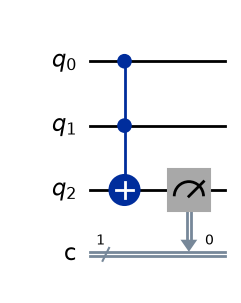

  AND(0,0) -> {'0': 100}


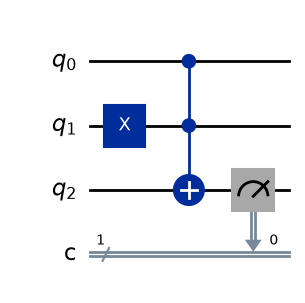

  AND(0,1) -> {'0': 100}


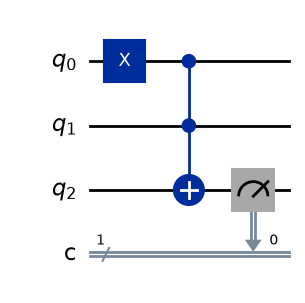

  AND(1,0) -> {'0': 100}


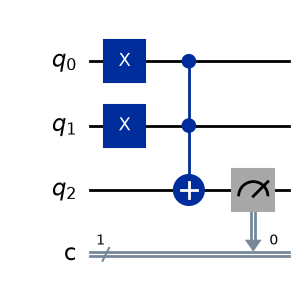

  AND(1,1) -> {'1': 100}


In [10]:
def and_gate(a, b):
    qc = QuantumCircuit(3, 1)
    if a: qc.x(0)
    if b: qc.x(1)
    qc.ccx(0, 1, 2)
    qc.measure(2, 0)
    display(qc.draw(output='mpl'))
    return run_circuit(qc, shots=100)

print("Tabla de verdad AND:")
for a in [0, 1]:
    for b in [0, 1]:
        print(f"  AND({a},{b}) ->", and_gate(a, b))

In [ ]:
def nand_gate(a, b):
    qc = QuantumCircuit(3, 1)
    if a: qc.x(0)
    if b: qc.x(1)
    qc.ccx(0, 1, 2)
    qc.x(2)  # invierte el resultado del AND
    qc.measure(2, 0)
    display(qc.draw(output='mpl'))
    return run_circuit(qc, shots=100)

print("Tabla de verdad NAND:")
for a in [0, 1]:
    for b in [0, 1]:
        print(f"  NAND({a},{b}) ->", nand_gate(a, b))


In [ ]:
def or_gate(a, b):
    # Fig. 5: dos CNOT + una Toffoli
    qc = QuantumCircuit(3, 1)
    if a: qc.x(0)
    if b: qc.x(1)
    qc.cx(0, 2)
    qc.cx(1, 2)
    qc.ccx(0, 1, 2)
    qc.measure(2, 0)
    display(qc.draw(output='mpl'))
    return run_circuit(qc, shots=100)

print("Tabla de verdad OR (método CNOT+CNOT+Toffoli):")
for a in [0, 1]:
    for b in [0, 1]:
        print(f"  OR({a},{b}) ->", or_gate(a, b))


También podemos mostrar el método alternativo de OR: invertir ambas entradas,
aplicar NAND, e invertir las entradas de vuelta — implementando
`q0 ∨ q1 = ¬(¬q0 ∧ ¬q1)`.


In [ ]:
def or_gate_alt(a, b):
    qc = QuantumCircuit(3, 1)
    if a: qc.x(0)
    if b: qc.x(1)
    qc.x(0); qc.x(1)      # Invertir entradas
    qc.ccx(0, 1, 2)
    qc.x(2)               # NAND = AND + X
    qc.x(0); qc.x(1)      # Restaurar entradas
    qc.measure(2, 0)
    display(qc.draw(output='mpl'))
    return run_circuit(qc, shots=100)

print("Tabla de verdad OR (método alternativo):")
for a in [0, 1]:
    for b in [0, 1]:
        print(f"  OR({a},{b}) ->", or_gate_alt(a, b))


### **Experimento 2:** SWAP de q0 y q1

Tres CNOT en secuencia (`CNOT(0,1)`, `CNOT(1,0)`, `CNOT(0,1)`) intercambian los estados de `q0` y `q1`. Probamos con los estados iniciales `q0=1` y `q1=0`, para verificar que el resultado es `q0=0` y `q1=1`.

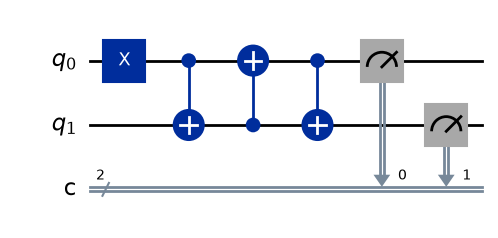

Resultado (esperado: q0=0, q1=1 -> bitstring '10' en formato Qiskit q1=1, q0=0): {'10': 100}


In [11]:
qc_swap = QuantumCircuit(2, 2)
qc_swap.x(0)  # q0=1, q1=0
qc_swap.cx(0, 1)
qc_swap.cx(1, 0)
qc_swap.cx(0, 1)
qc_swap.measure([0, 1], [0, 1])

display(qc_swap.draw(output='mpl'))
print("Resultado (esperado: q0=0, q1=1 -> bitstring '10' en formato Qiskit q1=1, q0=0):",
      run_circuit(qc_swap, shots=100))

### **Experimento 3:** Phase Kickback

Circuito `H-H` + `CNOT` con `q0` como control y `q1` como target + `H-H` que es equivalente a un `CNOT` con `q1` como control y `q0` como target. Probamos las 4 combinaciones de entrada y verificamos que: `00→00, 01→11, 10→10, 11→01`.

Phase Kickback - tabla de entradas/salidas:


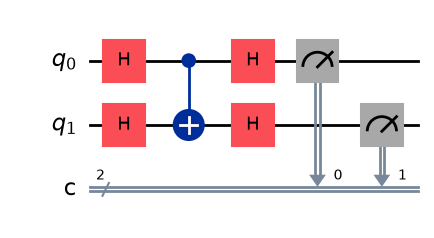

  input q0q1=00 -> counts: {'00': 100}


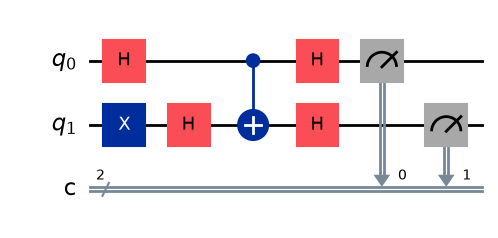

  input q0q1=01 -> counts: {'11': 100}


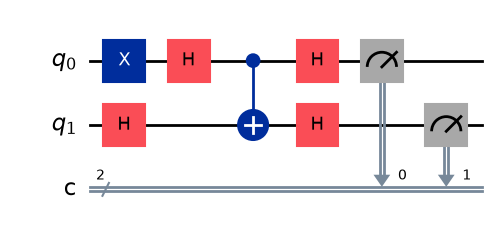

  input q0q1=10 -> counts: {'01': 100}


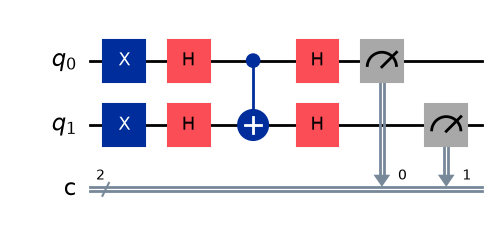

  input q0q1=11 -> counts: {'10': 100}


In [12]:
def phase_kickback(q0_init, q1_init):
    qc = QuantumCircuit(2, 2)
    if q0_init: qc.x(0)
    if q1_init: qc.x(1)
    qc.h(0); qc.h(1)
    qc.cx(0, 1)
    qc.h(0); qc.h(1)
    qc.measure([0, 1], [0, 1])
    display(qc.draw(output='mpl'))
    return run_circuit(qc, shots=100)

print("Phase Kickback - tabla de entradas/salidas:")
for q0i in [0, 1]:
    for q1i in [0, 1]:
        print(f"  input q0q1={q0i}{q1i} -> counts:", phase_kickback(q0i, q1i))


 ## **Referencias**

Notebook basada en el paper **"Understanding Quantum Parallelism through Programming"** (Sang & Yu, CSCI 2023), implementando en **Qiskit 2.4.2** los circuitos descritos en la Sección III, Labs 1 a 7. Se han agregado experimentos adicionales para incorporar otros temas.